**AICE Associate <font color=red>모의고사 (문제)</font>** — AICE_Asso_029_초급_회귀_물류배송지연예측

### **물류 배송 지연 예측 — <span style="color:darkgreen">지연 시간(분)</span> 예측 모델 개발**
---

- 도메인 : 물류 배송 지연 예측
- 목  표 : 배송 지연 시간(분)을 예측하는 인공지능모델 개발
- 운영팀은 출발 전 배차 정보로 지연 가능성을 미리 예측해 배차를 조정하려 한다.
- 배송 지연 민원이 늘어 소담로지스의 고객 만족도와 재계약률이 떨어지고 있다.
- 배송 건 3,100건 안팎의 이력 데이터를 활용할 수 있다.
- 지연 시간(분)을 미리 알 수 있다면 소담로지스의 운영 효율이 크게 개선될 것으로 보고 있다.

---

#### **[유의사항]**
- 각 문항의 답은 `# (번호) 정답을 입력하세요` 셀의 `정답01` ~ `정답14` 변수에 **값만** 입력합니다. 채점은 이 값으로만 합니다.
- 숫자는 문항이 안내한 자릿수로 반올림해 입력하고, 글자는 따옴표로 감싸 입력하세요(예: `정답01 = 'pandas'`).
- 답을 구하는 코드는 문항의 작업 셀에 작성하고 실행하세요. 제공된 문항 셀을 삭제하지 마세요.
- 문항에 변수명이 제시된 경우 반드시 해당 변수명을 사용하세요. 앞 문항의 결과를 뒤 문항이 이어서 사용합니다.
- 막히면 문항 아래 접혀 있는 **힌트 1·2·3단계**를 순서대로 펼쳐 보세요. 단계가 올라갈수록 정답에 가까워집니다.
- 모든 데이터는 가상으로 생성한 합성데이터이며, 실제 AICE 시험문항의 원문을 복제하지 않았습니다.

#### **[학습 정보]**
- 학습 목표 : 소담로지스의 데이터로 배송 지연 시간(분)을 예측하는 AI 모델을 만들며 데이터 분석·전처리·모델링 전 과정을 수행할 수 있다
- AICE 역량 : 데이터 분석(DA1 분석 환경 구성, DA2 데이터 불러오기·구조 파악, DA3 탐색적 데이터 분석, DA4 데이터 시각화) / 데이터 전처리(DP1 이상치 처리, DP2 결측치 처리, DP3 인코딩·변수 변환, DP4 데이터 분할, DP5 스케일링) / AI 모델링(AM1 머신러닝 모델 학습·탐색, AM2 모델 해석, AM3 모델 성능 평가, AM4 딥러닝 모델 구성·학습, AM5 딥러닝 학습 결과 분석)
- 기술 스택 : pandas(import pandas as pd, read_csv, head, value_counts, dtypes, dropna, quantile, copy, clip, drop, sum, isnull, get_dummies, sort_values, Series, columns, shape) · NumPy(import numpy as np, abs) · matplotlib(figure, hist, title, xlabel, ylabel, tight_layout, show, plot, legend) · scikit-learn(LabelEncoder, fit_transform, train_test_split, StandardScaler, transform, LinearRegression, fit, RandomForestRegressor, coef_, predict, r2_score) · TensorFlow(Keras)(Sequential, EarlyStopping, ModelCheckpoint, compile, fit, Dense, Dropout, history)
- 난이도 : 초급 (설계 난이도 점수 2.49 / 5)
- 예상 소요 시간 : 약 113분 (문항별 시간은 각 문항 제목 아래)
- 관련 도메인 : 물류 배송 지연 예측 (교통·물류)

**[ 데이터 컬럼 설명 (데이터 파일명: data.csv) ]**

- delayMin              : 지연 시간(분)
- recordId              : 레코드 식별번호
- distanceKm            : 배송 거리(km)
- weightKg              : 화물 중량(kg)
- nStops                : 경유지 수
- trafficIdx            : 교통 혼잡 지수
- tempC                 : 기온(℃)
- driverExpY            : 기사 경력(년)
- fuelPrice             : 유가(원/L)
- carrier               : 운송사
- vehicle               : 차량 종류
- weather               : 날씨
- routeType             : 노선 유형

## <font color=blue>**<데이터 분석 (20점)>**</font>

> **<span style="color:red">다음 문항을 풀기 전에 </span>아래 코드를 실행하세요.**

In [1]:
import seaborn as sns
import matplotlib.pyplot as plt

### **1. 수치 계산을 위해 NumPy 라이브러리를 사용하려고 합니다. 아래 가이드의 별칭(alias)으로 불러오세요.**

<sub>학습 목표: 분석에 필요한 파이썬 라이브러리를 관용 별칭으로 불러올 수 있다 | 역량: DA1 분석 환경 구성 | 기술: NumPy(import numpy as np) | 난이도: 기초 | 예상 시간: 3분</sub>

- 불러올 라이브러리 : `numpy`
- 별칭(alias) : `np`
- 아래 코드 셀(cell)의 코드를 실행해 결과를 확인하세요 — 빈칸(____)은 한 곳입니다
- **[정답01]** 아래 코드 셀의 빈칸(____)에 들어갈 내용(함수·인자·모듈 이름)을 입력하세요
- 답안 : **[정답01]** 의 값만 답안 셀에 `정답01 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 5점

---

In [2]:
# (코드 셀) 코드의 빈칸(____)을 채우고 실행하세요

import numpy as np

In [ ]:
# (1) 정답을 입력하세요 — `정답01` 에 값만 넣고 실행하세요

정답01 = 'numpy'

<details><summary>힌트 1단계 (접근 방향) - 1번 문항</summary>

`import 라이브러리 as 별칭` 문법으로 라이브러리를 불러옵니다. 코드의 흐름(앞뒤 변수와 인자)을 보고 이 자리에 들어갈 함수·옵션 이름을 떠올려 보세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 1번 문항</summary>

사용할 도구: `import ... as ...`. 정답은 5글자이고 첫 글자는 `n` 입니다.

</details>

<details><summary>힌트 3단계 (전체 코드) - 1번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 빈칸(____) 자리의 단어는 앞 글자만 보여 줍니다.
```python
import num__ as np

정답01 = 'num__'   # 빈칸에 넣은 단어
```

</details>

### **2. 모델을 만들 데이터를 파일에서 읽어 들이려 합니다. pandas로 데이터 파일을 읽어온 뒤, 데이터프레임 변수명 data 에 할당하고 첫 5개 행을 출력하세요.**

<sub>학습 목표: CSV 파일을 데이터프레임으로 읽고 행·열 구성을 확인할 수 있다 | 역량: DA2 데이터 불러오기·구조 파악 | 기술: pandas(import pandas as pd, read_csv, head) | 난이도: 기초 | 예상 시간: 4분</sub>

- 제시된 가이드에 맞춰 코드를 작성하고 실행하세요
    - 파일은 본 문제/답안지와 동일한 경로에 있습니다
    - 읽어 올 파일 : data.csv / 데이터프레임 변수명 : data
- **[정답02]** 읽어 온 데이터의 **숫자형이 아닌(문자열) 컬럼의 개수** 를 기입하세요
- 답안 : **[정답02]** 의 값만 답안 셀에 `정답02 = 값` 형태로 입력하세요
- 배점 : 5점

---

In [3]:
# 작업 셀 : 가이드에 따라 코드를 작성하고 실행하세요 (채점하지 않음)

import pandas as pd

data = pd.read_csv('./data.csv')
data.head(5)

print(data.select_dtypes(exclude='number').shape[1])


4


In [ ]:
# (2) 정답을 입력하세요 — `정답02` 에 값만 넣고 실행하세요

정답02 = 4

<details><summary>힌트 1단계 (접근 방향) - 2번 문항</summary>

파일 형식(csv/json/구분자)에 맞는 pandas 읽기 함수와 옵션을 고르세요. 읽어 온 data 로 숫자형이 아닌(문자열) 컬럼의 개수를 직접 확인하세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 2번 문항</summary>

사용할 도구: `pd.read_csv`, `shape`, `select_dtypes`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 2번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 코드를 그대로 실행해 마지막 줄의 결과를 정답으로 입력하세요.
```python
import pandas as pd

data = pd.read_csv('./data.csv')
data.head(5)

# [정답02] `__`·`____` 자리를 채워 실행한 결과를 입력하세요
print(data.select_dtypes(exclude='____').shape[__])
```

</details>

### **3. 데이터를 모델링에 쓰기 전에 컬럼들의 자료형 구성을 확인하려 합니다.**

<sub>학습 목표: 집계·통계량으로 데이터의 특징을 탐색할 수 있다 | 역량: DA3 탐색적 데이터 분석 | 기술: pandas(value_counts, dtypes) | 난이도: 기초 | 예상 시간: 3분</sub>

- 앞 문항 결과 사용 : 2번 `data`
- data 의 `dtypes` 를 이용해 자료형별 컬럼 개수를 구하고(value_counts) 변수 `type_counts` 에 저장한 뒤 출력하세요
- 아래 코드 셀(cell)의 코드를 실행해 결과를 확인하세요 — 빈칸(____)은 한 곳입니다
- **[정답03]** 아래 코드 셀의 빈칸(____)에 들어갈 내용(함수·인자·모듈 이름)을 입력하세요
- 답안 : **[정답03]** 의 값만 답안 셀에 `정답03 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 5점

---

In [4]:
# (코드 셀) 코드의 빈칸(____)을 채우고 실행하세요

type_counts = data.dtypes.value_counts()
print(type_counts)

float64    8
object     4
int64      1
Name: count, dtype: int64


In [ ]:
# (3) 정답을 입력하세요 — `정답03` 에 값만 넣고 실행하세요

정답03 = 'value_counts'

<details><summary>힌트 1단계 (접근 방향) - 3번 문항</summary>

컬럼별 자료형 속성에 개수 세기 메서드를 이어 붙입니다. 코드의 흐름(앞뒤 변수와 인자)을 보고 이 자리에 들어갈 함수·옵션 이름을 떠올려 보세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 3번 문항</summary>

사용할 도구: `dtypes`, `value_counts`. 정답은 12글자이고 첫 글자는 `v` 입니다.

</details>

<details><summary>힌트 3단계 (전체 코드) - 3번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 빈칸(____) 자리의 단어는 앞 글자만 보여 줍니다.
```python
type_counts = data.dtypes.value_______()
print(type_counts)

정답03 = 'value_______'   # 빈칸에 넣은 단어
```

</details>

### **4. 경유지 수(nStops)의 분포를 matplotlib 으로 직접 그려 확인하려 합니다.**

<sub>학습 목표: 그래프로 변수의 분포와 관계를 시각화할 수 있다 | 역량: DA4 데이터 시각화 | 기술: pandas(dropna) · matplotlib(figure, hist, title, xlabel) | 난이도: 쉬움 | 예상 시간: 4분</sub>

- 앞 문항 결과 사용 : 2번 `data`
- `plt.figure` 로 그림 크기를 (가로 10, 세로 5)(figsize)로 설정하세요
    - `plt.hist` 로 data 의 nStops (결측치 제외, `dropna()`)의 히스토그램을 구간 30개(bins=30)로 그리고, 반환값을 `counts, edges, patches` 에 받으세요
    - 제목(`plt.title`)에 'nStops distribution', x축 이름(`plt.xlabel`)에 'nStops', y축 이름(`plt.ylabel`)에 'count' 를 쓰세요
    - `plt.tight_layout()` 으로 여백을 정리하고 `plt.show()` 로 출력하세요
- 아래 코드 셀(cell)의 코드를 실행해 결과를 확인하세요 — 빈칸(____)은 한 곳입니다
- **[정답04]** 아래 코드 셀의 빈칸(____)에 들어갈 내용(함수·인자·모듈 이름)을 입력하세요
- 답안 : **[정답04]** 의 값만 답안 셀에 `정답04 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 5점

---

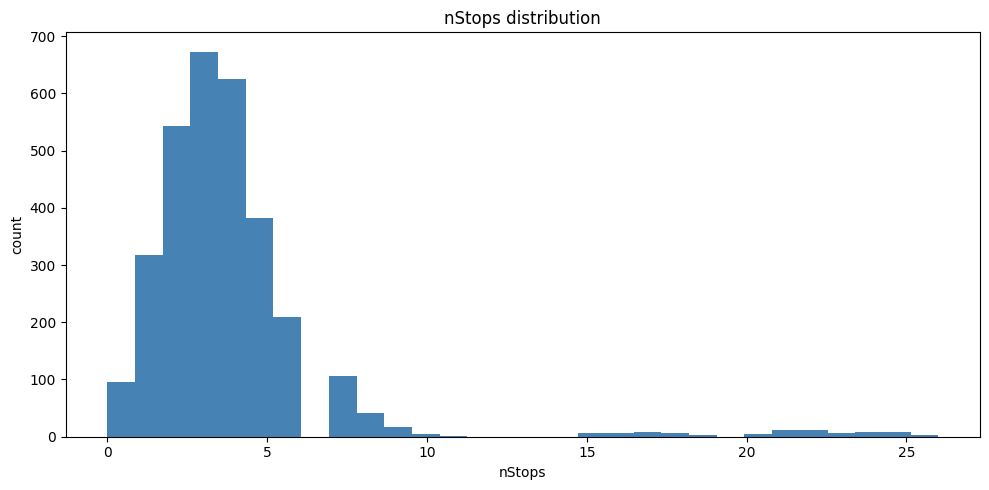

In [5]:
# (코드 셀) 코드의 빈칸(____)을 채우고 실행하세요

plt.figure(figsize=(10, 5))
counts, edges, patches = plt.hist(data['nStops'].dropna(), bins=30, color='steelblue')
plt.title('nStops distribution')
plt.xlabel('nStops')
plt.ylabel('count')
plt.tight_layout()
plt.show()

In [ ]:
# (4) 정답을 입력하세요 — `정답04` 에 값만 넣고 실행하세요

정답04 = 'hist'

<details><summary>힌트 1단계 (접근 방향) - 4번 문항</summary>

그림 크기를 정하고 히스토그램을 그린 뒤 제목·축 이름·여백을 정리하는 matplotlib 함수들을 순서대로 쓰세요. 코드의 흐름(앞뒤 변수와 인자)을 보고 이 자리에 들어갈 함수·옵션 이름을 떠올려 보세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 4번 문항</summary>

사용할 도구: `plt.figure`, `plt.hist`, `plt.title`, `plt.tight_layout`. 정답은 4글자이고 첫 글자는 `h` 입니다.

</details>

<details><summary>힌트 3단계 (전체 코드) - 4번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 빈칸(____) 자리의 단어는 앞 글자만 보여 줍니다.
```python
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
counts, edges, patches = plt.hi__(data['nStops'].dropna(), bins=30, color='steelblue')
plt.title('nStops distribution')
plt.xlabel('nStops')
plt.ylabel('count')
plt.tight_layout()
plt.show()

정답04 = 'hi__'   # 빈칸에 넣은 단어
```

</details>

## <font color=blue>**<데이터 전처리 (30점)>**</font>

### **5. 경유지 수(nStops) 컬럼의 극단값을 상·하위 5% 경계값으로 대체하고자 합니다.**

<sub>학습 목표: 사분위 범위(IQR) 등의 기준으로 이상치를 찾아 처리할 수 있다 | 역량: DP1 이상치 처리 | 기술: pandas(quantile, copy, clip, drop) | 난이도: 보통 | 예상 시간: 10분</sub>

- 앞 문항 결과 사용 : 2번 `data`
- 아래 안내대로 코드를 작성하고 실행하세요
    - 대상 데이터프레임 : data
    - nStops 의 5% 분위수를 low, 95% 분위수를 high 로 계산하세요 (변수명: low, high)
    - low 보다 작은 값은 low 로, high 보다 큰 값은 high 로 바꾸세요(행 삭제 없음)
    - 식별자 컬럼 recordId 를 삭제한 사본에 적용해 data_temp 에 보관하세요
- **[정답05]** 처리 후 nStops 의 **최솟값**을 소수 둘째 자리까지 작성하세요
- 답안 : **[정답05]** 의 값만 답안 셀에 `정답05 = 값` 형태로 입력하세요
- 배점 : 6점

---

In [6]:
# 작업 셀 : 가이드에 따라 코드를 작성하고 실행하세요 (채점하지 않음)

low, high = data['nStops'].quantile([0.05, 0.95])

data_temp = data.drop(columns=['recordId']).copy()
data_temp['nStops'] = data_temp['nStops'].clip(lower=low, upper=high)

data_temp['nStops'].min()


1.0

In [ ]:
# (5) 정답을 입력하세요 — `정답05` 에 값만 넣고 실행하세요

정답05 = '1.0'

<details><summary>힌트 1단계 (접근 방향) - 5번 문항</summary>

분위수 두 개를 한 번에 구한 뒤 clip 에 하한/상한으로 넣습니다. 처리된 컬럼의 최솟값은 low 이상 high 이하입니다.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 5번 문항</summary>

사용할 도구: `quantile`, `clip`, `min`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 5번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 코드를 그대로 실행해 마지막 줄의 결과를 정답으로 입력하세요.
```python
low, high = data['nStops'].quantile([0.05, 0.95])

data_temp = data.drop(columns=['recordId']).copy()
data_temp['nStops'] = data_temp['nStops'].clip(lower=low, upper=high)

# [정답05] `__`·`____` 자리를 채워 실행한 결과를 입력하세요
data_temp['____'].min()
```

</details>

### **6. 데이터에 결측치가 있을 경우 AI모델링의 성능이 저하될 수 있습니다. AI모델링할 때 부정적 영향이 없도록 제시된 가이드에 맞춰 결측치를 처리하십시오.**

<sub>학습 목표: 결측치를 확인하고 삭제하거나 대체할 수 있다 | 역량: DP2 결측치 처리 | 기술: pandas(dropna, sum, isnull) | 난이도: 쉬움 | 예상 시간: 6분</sub>

- 앞 문항 결과 사용 : 5번 `data_temp`
- 대상 데이터프레임 : data_temp
- 결측치 개수를 확인한 후에 결측치가 있는 행을 모두 삭제하세요
- 전처리가 반영된 데이터프레임은 변수명 data_na 에 담으세요
- 결측치가 사라졌는지 확인하세요
- 아래 코드 셀(cell)의 코드를 실행해 결과를 확인하세요 — 빈칸(____)은 한 곳입니다
- **[정답06]** 아래 코드 셀의 빈칸(____)에 들어갈 내용(함수·인자·모듈 이름)을 입력하세요
- 답안 : **[정답06]** 의 값만 답안 셀에 `정답06 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 6점

---

In [7]:
# (코드 셀) 코드의 빈칸을 채우고 실행하세요

print( '결측치 처리 전\n', data_temp.isnull().sum() )
data_na = data_temp.dropna()
print( '결측치 처리 후\n', data_na.isnull().sum() )

결측치 처리 전
 delayMin        0
distanceKm    157
weightKg        0
nStops          0
trafficIdx      0
tempC           0
driverExpY      0
fuelPrice       0
carrier         0
vehicle         0
weather         0
routeType       0
dtype: int64
결측치 처리 후
 delayMin      0
distanceKm    0
weightKg      0
nStops        0
trafficIdx    0
tempC         0
driverExpY    0
fuelPrice     0
carrier       0
vehicle       0
weather       0
routeType     0
dtype: int64


In [ ]:
# (6) 정답을 입력하세요 — `정답06` 에 값만 넣고 실행하세요

정답06 = 'dropna'

<details><summary>힌트 1단계 (접근 방향) - 6번 문항</summary>

빈칸을 채워 코드를 완성한 뒤 실행하세요. 결측치가 있는 행을 삭제하는 메서드입니다.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 6번 문항</summary>

사용할 도구: `isnull`, `sum`, `dropna`. 정답은 6글자이고 첫 글자는 `d` 입니다.

</details>

<details><summary>힌트 3단계 (전체 코드) - 6번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 빈칸(____) 자리의 단어는 앞 글자만 보여 줍니다.
```python
print( '결측치 처리 전\n', data_temp.isnull().sum() )
data_na = data_temp.dro___()
print( '결측치 처리 후\n', data_na.isnull().sum() )

정답06 = 'dro___'   # 빈칸에 넣은 단어
```

</details>

### **7. 범주형 컬럼의 특성에 따라 인코딩 방식을 달리 적용하려 합니다. 다음 지침에 따라 인코딩하세요.**

<sub>학습 목표: 범주형 변수를 인코딩하고 변수를 정리·변환할 수 있다 | 역량: DP3 인코딩·변수 변환 | 기술: pandas(copy, get_dummies) · scikit-learn(LabelEncoder, fit_transform) | 난이도: 보통 | 예상 시간: 10분</sub>

- 앞 문항 결과 사용 : 2번 `pd` · 6번 `data_na`
- 아래 안내대로 코드를 작성하고 실행하세요
    - 대상 데이터프레임 : data_na
    - 노선 유형(routeType) 는 sklearn **LabelEncoder** 로 정수 인코딩하세요
    - 나머지 문자열 컬럼 carrier, vehicle, weather 은(는) get_dummies(drop_first=True)로 원-핫 인코딩하세요
    - 결과는 data_preset 에 저장하세요
- **[정답07]** 인코딩 후 data_preset 의 **전체 컬럼 개수**는 몇 개인가요?
- 답안 : **[정답07]** 의 값만 답안 셀에 `정답07 = 값` 형태로 입력하세요
- 배점 : 6점

---

In [8]:
# 작업 셀 : 가이드에 따라 코드를 작성하고 실행하세요 (채점하지 않음)

from sklearn.preprocessing import LabelEncoder

data_preset = data_na.copy()
le = LabelEncoder()
data_preset['routeType'] = le.fit_transform(data_preset['routeType'])
data_preset = pd.get_dummies(data=data_preset, columns=['carrier', 'vehicle', 'weather'], drop_first=True)

data_preset.shape[1]


18

In [ ]:
# (7) 정답을 입력하세요 — `정답07` 에 값만 넣고 실행하세요

정답07 = '18'

<details><summary>힌트 1단계 (접근 방향) - 7번 문항</summary>

한 컬럼은 정수 라벨로, 나머지는 0/1 컬럼으로 바꿉니다. 인코딩이 끝난 데이터프레임의 컬럼 개수를 확인하세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 7번 문항</summary>

사용할 도구: `LabelEncoder`, `fit_transform`, `pd.get_dummies`, `shape`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 7번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 코드를 그대로 실행해 마지막 줄의 결과를 정답으로 입력하세요.
```python
import pandas as pd

from sklearn.preprocessing import LabelEncoder

data_preset = data_na.copy()
le = LabelEncoder()
data_preset['routeType'] = le.fit_transform(data_preset['routeType'])
data_preset = pd.get_dummies(data=data_preset, columns=['carrier', 'vehicle', 'weather'], drop_first=True)

# [정답07] `__`·`____` 자리를 채워 실행한 결과를 입력하세요
data_preset.shape[__]
```

</details>

### **8. 학습한 모델을 공정하게 평가하려면 학습에 쓰지 않은 검증 데이터가 필요합니다. 데이터를 훈련용과 검증용으로 나누려 합니다. 다음 지침에 따라 분리하십시오.**

<sub>학습 목표: 피처와 레이블을 나누고 훈련·검증 데이터로 분할할 수 있다 | 역량: DP4 데이터 분할 | 기술: pandas(drop) · scikit-learn(train_test_split) | 난이도: 쉬움 | 예상 시간: 6분</sub>

- 앞 문항 결과 사용 : 7번 `data_preset`
- 대상 데이터프레임 : data_preset
- 지연 시간(분)(delayMin) 컬럼을 레이블값 y 로, 나머지 컬럼을 피처값 X 로 할당하세요
- scikit-learn 의 train_test_split 함수를 활용하세요
- 분리 결과는 X_train, X_valid, y_train, y_valid 순서로 받으세요
- 훈련 75%, 검증 25% 비율로 나누세요 (test_size=0.25)
- random_state 는 11 로 고정하세요
- 아래 코드 셀(cell)의 코드를 실행해 결과를 확인하세요 — 빈칸(____)은 한 곳입니다
- **[정답08]** 아래 코드 셀의 빈칸(____)에 들어갈 내용(함수·인자·모듈 이름)을 입력하세요
- 답안 : **[정답08]** 의 값만 답안 셀에 `정답08 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 6점

---

In [9]:
# (코드 셀) 코드의 빈칸(____)을 채우고 실행하세요

from sklearn.model_selection import train_test_split

X = data_preset.drop('delayMin', axis=1)
y = data_preset['delayMin']

X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.25, random_state=11)

In [ ]:
# (8) 정답을 입력하세요 — `정답08` 에 값만 넣고 실행하세요

정답08 = 'test_size'

<details><summary>힌트 1단계 (접근 방향) - 8번 문항</summary>

피처와 레이블을 나눈 뒤, 훈련/검증으로 무작위 분할합니다. 코드의 흐름(앞뒤 변수와 인자)을 보고 이 자리에 들어갈 함수·옵션 이름을 떠올려 보세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 8번 문항</summary>

사용할 도구: `train_test_split`, `drop`. 정답은 9글자이고 첫 글자는 `t` 입니다.

</details>

<details><summary>힌트 3단계 (전체 코드) - 8번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 빈칸(____) 자리의 단어는 앞 글자만 보여 줍니다.
```python
from sklearn.model_selection import train_test_split

X = data_preset.drop('delayMin', axis=1)
y = data_preset['delayMin']

X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_____=0.25, random_state=11)

정답08 = 'test_____'   # 빈칸에 넣은 단어
```

</details>

### **9. 스케일링을 통해 변수들의 단위(범위) 차이가 모델에 미치는 영향을 줄이려 합니다. (표준화(평균 0, 표준편차 1))**

<sub>학습 목표: 훈련 데이터로 스케일러를 학습해 검증 데이터에 같은 기준을 적용할 수 있다 | 역량: DP5 스케일링 | 기술: scikit-learn(StandardScaler, fit_transform, transform) | 난이도: 보통 | 예상 시간: 10분</sub>

- 앞 문항 결과 사용 : 8번 `X_train`, `X_valid`
- 제시된 가이드에 맞춰 스케일링 처리하는데 에러가 나고 있습니다. 코드의 오류를 수정하세요
    - sklearn.preprocessing 에서 StandardScaler 를 import 하세요
    - StandardScaler 를 scaler 변수에 할당하세요
    - 훈련 데이터(X_train)에 대해 스케일러를 학습시키고 변환을 적용해 X_train 에 다시 저장하세요
    - 검증 데이터(X_valid)에는 **학습된 기준을 그대로** 적용(변환만)해 X_valid 에 담으세요
- **[정답09]** StandardScaler 적용 후 검증 데이터(X_valid)의 **최댓값**을 소수점 둘째 자리까지 작성하세요
- 답안 : **[정답09]** 의 값만 답안 셀에 `정답09 = 값` 형태로 입력하세요
- 배점 : 6점

---

In [10]:
# 작업 셀 : 아래 코드의 오류를 정정하고 실행하세요 (채점하지 않음)

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_valid = scaler.transform(X_valid)

round(np.max(X_valid), 2)

np.float64(13.33)

In [ ]:
# (9) 정답을 입력하세요 — `정답09` 에 값만 넣고 실행하세요

정답09 = '13.33'

<details><summary>힌트 1단계 (접근 방향) - 9번 문항</summary>

훈련 데이터로 fit, 검증 데이터는 transform 만 하는 규칙을 떠올리세요. 변환된 검증 데이터 전체에서 최댓값을 구하세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 9번 문항</summary>

사용할 도구: `np.max`, `round`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 9번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 코드를 그대로 실행해 마지막 줄의 결과를 정답으로 입력하세요.
```python
import numpy as np

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_valid = scaler.transform(X_valid)

# [정답09] `__`·`____` 자리를 채워 실행한 결과를 입력하세요
round(np.max(X_valid), __)
```

</details>

## <font color=blue>**<AI 모델링 (50점)>**</font>

### **10. 지연 시간(분)(delayMin)을(를) 예측하는 머신러닝 모델을 만들려고 합니다. LinearRegression와(과) RandomForest는 각각 서로 다른 방식으로 예측하는 모델입니다.**

<sub>학습 목표: 머신러닝 모델에 하이퍼파라미터를 지정해 학습하고 결과를 확인할 수 있다 | 역량: AM1 머신러닝 모델 학습·탐색 | 기술: scikit-learn(LinearRegression, fit, RandomForestRegressor) | 난이도: 쉬움 | 예상 시간: 10분</sub>

- 앞 문항 결과 사용 : 8번 `y_train` · 9번 `X_train`
- LinearRegression 모델을 아래와 같이 만들어 `lin` 변수에 저장하고 학습시키세요
    - 하이퍼파라미터 : 지정하지 않음(기본값)
    - 앞서 분리한 훈련데이터셋(X_train, y_train)으로 fit 함수를 사용해 학습시키세요
- RandomForest 모델을 아래와 같이 만들어 `rf` 변수에 저장하고 학습시키세요
    - 하이퍼파라미터 : n_estimators=150, max_depth=4
    - 난수 시드(random_state) : 0
    - 앞서 분리한 훈련데이터셋(X_train, y_train)으로 fit 함수를 사용해 학습시키세요
- **[정답10]** 학습된 `lin`(LinearRegression) 의 절편(`intercept_`)을 소수점 둘째 자리까지 기입하세요
- 답안 : **[정답10]** 의 값만 답안 셀에 `정답10 = 값` 형태로 입력하세요
- 배점 : 10점

---

In [11]:
# 작업 셀 : 가이드에 따라 코드를 작성하고 실행하세요 (채점하지 않음)

from sklearn.linear_model import LinearRegression

lin = LinearRegression()
lin.fit(X_train, y_train)

from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(n_estimators=150, max_depth=4, random_state=0)
rf.fit(X_train, y_train)

round(lin.intercept_, 2)


np.float64(26.83)

In [ ]:
# (10) 정답을 입력하세요 — `정답10` 에 값만 넣고 실행하세요

정답10 = '26.83'

<details><summary>힌트 1단계 (접근 방향) - 10번 문항</summary>

모델 객체를 하이퍼파라미터와 함께 만들고 훈련 데이터로 fit 합니다. 선형 모델은 학습 후 intercept_ 속성에 절편을 저장합니다.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 10번 문항</summary>

사용할 도구: `LinearRegression`, `fit`, `RandomForestRegressor`, `intercept_`, `round`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 10번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 코드를 그대로 실행해 마지막 줄의 결과를 정답으로 입력하세요.
```python
from sklearn.linear_model import LinearRegression

lin = LinearRegression()
lin.fit(X_train, y_train)

from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(n_estimators=150, max_depth=4, random_state=0)
rf.fit(X_train, y_train)

# [정답10] `__`·`____` 자리를 채워 실행한 결과를 입력하세요
round(lin.intercept_, __)
```

</details>

### **11. 선형회귀 모델의 계수 크기로 어떤 변수가 예측에 큰 영향을 주는지 해석하고자 합니다.**

<sub>학습 목표: 변수 중요도·계수로 모델이 어떤 변수에 의존하는지 해석할 수 있다 | 역량: AM2 모델 해석 | 기술: pandas(sort_values, Series, columns) · NumPy(abs) · scikit-learn(coef_) | 난이도: 보통 | 예상 시간: 12분</sub>

- 앞 문항 결과 사용 : 1번 `np` · 2번 `pd` · 8번 `X` · 10번 `lin`
- 학습된 lin 의 계수(`coef_`)의 **절댓값**을 변수명(X.columns)과 매핑한 Series 로 만들어 내림차순 정렬한 뒤 `coef_s` 에 저장하세요
- **[정답11]** 계수 절댓값이 **가장 큰 변수명**을 쓰세요
- 답안 : **[정답11]** 의 값만 답안 셀에 `정답11 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 10점

---

In [12]:
# 작업 셀 : 가이드에 따라 코드를 작성하고 실행하세요 (채점하지 않음)


coef_s = pd.Series(np.abs(lin.coef_), index=X.columns).sort_values(ascending=False)

coef_s.index[0]


'distanceKm'

In [ ]:
# (11) 정답을 입력하세요 — `정답11` 에 값만 넣고 실행하세요

정답11 = 'distanceKm'

<details><summary>힌트 1단계 (접근 방향) - 11번 문항</summary>

학습된 계수의 절댓값을 변수명과 묶어 정렬합니다. coef_s 의 첫 번째 인덱스를 확인하세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 11번 문항</summary>

사용할 도구: `coef_`, `np.abs`, `sort_values`, `index`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 11번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 코드를 그대로 실행해 마지막 줄의 결과를 정답으로 입력하세요.
```python
import pandas as pd
import numpy as np

coef_s = pd.Series(np.abs(lin.coef_), index=X.columns).sort_values(ascending=False)

# [정답11] `__`·`____` 자리를 채워 실행한 결과를 입력하세요
coef_s.index[__]
```

</details>

### **12. 앞서 학습시킨 LinearRegression와(과) RandomForest 모델의 성능을 평가하려고 합니다.**

<sub>학습 목표: 평가 지표로 두 모델의 성능을 비교할 수 있다 | 역량: AM3 모델 성능 평가 | 기술: scikit-learn(predict, r2_score) | 난이도: 보통 | 예상 시간: 12분</sub>

- 앞 문항 결과 사용 : 8번 `y_valid` · 9번 `X_valid` · 10번 `lin`, `rf`
- 다음 지침에 따라 각 모델의 R2(결정계수) 를 산출하려는데 오류가 발생하고 있습니다. 코드의 오류를 수정하세요
    - 앞서 학습시킨 lin 와 rf 모델을 사용하세요
    - 성능 평가는 **검증데이터셋(X_valid, y_valid)** 을 활용하세요
    - 두 모델의 R2(결정계수) 값을 각각 linreg_score, rf_score 변수에 저장하고 출력하세요
- **[정답12]** 두 모델의 R2(결정계수) 결과를 비교했을 때, 성능이 **더 우수한** 모델은 무엇인가요? (LinearRegression / RandomForest 중 하나)
- 답안 : **[정답12]** 의 값만 답안 셀에 `정답12 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 10점

---

In [13]:
# 작업 셀 : 아래 코드의 오류를 정정하고 실행하세요 (채점하지 않음)

from sklearn.metrics import r2_score

y_pred_linreg = lin.predict(X_valid)
y_pred_rf = rf.predict(X_valid)

linreg_score = r2_score(y_valid, y_pred_linreg)
rf_score = r2_score(y_valid, y_pred_rf)
print(linreg_score, rf_score)

0.45753290431849347 0.5939666108151959


In [ ]:
# (12) 정답을 입력하세요 — `정답12` 에 값만 넣고 실행하세요

정답12 = 'RandomForest'

<details><summary>힌트 1단계 (접근 방향) - 12번 문항</summary>

R2(결정계수) 를 계산하는 흐름(예측 -> 지표 함수)을 점검하세요. 값이 클수록 우수한 지표입니다. 두 점수를 비교하세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 12번 문항</summary>

가이드에 언급된 함수를 확인하세요.

</details>

<details><summary>힌트 3단계 (전체 코드) - 12번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 코드를 그대로 실행해 마지막 줄의 결과를 정답으로 입력하세요.
```python
from sklearn.metrics import r2_score

y_pred_linreg = lin.predict(X_valid)
y_pred_rf = rf.predict(X_valid)

linreg_score = r2_score(y_valid, y_pred_linreg)
rf_score = r2_score(y_valid, y_pred_rf)
print(linreg_score, rf_score)

# [정답12] 실행한 결과를 입력하세요
print(linreg_score, rf_score)
```

</details>

> **<span style="color:red">다음 문항을 풀기 전에 </span>아래 코드를 실행하세요. (tensorflow 필요)**

In [14]:
import tensorflow as tf
from tensorflow.keras.models import Sequential, Model, load_model
from tensorflow.keras.layers import Input, Dense, Activation, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam, RMSprop, Nadam, SGD
from tensorflow.keras.regularizers import l2
from tensorflow.keras.utils import to_categorical

tf.random.set_seed(1)

### **13. 지연 시간(분)(delayMin)을(를) 예측하는 딥러닝 모델을 만들려고 합니다. 아래 조건대로 모델을 만들고 학습시키세요.**

<sub>학습 목표: 주어진 구조대로 Keras 딥러닝 모델을 구성하고 학습할 수 있다 | 역량: AM4 딥러닝 모델 구성·학습 | 기술: pandas(shape) · TensorFlow(Keras)(Sequential, EarlyStopping, ModelCheckpoint, compile) | 난이도: 보통 | 예상 시간: 13분</sub>

- 앞 문항 결과 사용 : 8번 `y_train`, `y_valid` · 9번 `X_train`, `X_valid`
- tensorflow framework 를 사용하세요
- Dense 은닉층 2개를 노드 수 [64, 32] 순서로 쌓고, 활성화 함수는 'tanh' 를 쓰세요
- 모든 은닉층 뒤에 Dropout(0.5) 층을 두세요 / val_loss 가 10 epoch 연속 좋아지지 않으면 멈추는 EarlyStopping(restore_best_weights=True)을 estop 변수에 담으세요
- ModelCheckpoint('best_model.keras', save_best_only=True)를 callbacks 에 함께 넣으세요
- 출력층: 노드 1개 (회귀이므로 활성화 함수 없음)
- compile 설정 : optimizer='adam', loss='mse', metrics=[mae, mse]
- batch_size 는 16, epochs 는 30 로 학습하고 학습정보는 history 변수에 담으세요 (검증 데이터: X_valid, 검증 레이블)
- 가이드에 없는 인자는 추가하지 말고 기본값으로 두세요
- 아래 코드 셀(cell)의 코드를 실행해 결과를 확인하세요 — 빈칸(____)은 한 곳입니다
- **[정답13]** 아래 코드 셀의 빈칸(____)에 들어갈 내용(함수·인자·모듈 이름)을 입력하세요
- 답안 : **[정답13]** 의 값만 답안 셀에 `정답13 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 10점

---

In [15]:
# (코드 셀) 코드의 빈칸을 채우고 실행하세요

model = Sequential([
    Dense(64, activation='tanh', input_dim=X_train.shape[1]),
    Dropout(0.5),
    Dense(32, activation='tanh'),
    Dropout(0.5),
    Dense(1)
])

estop = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)
cb_list = [estop]
ckpt = ModelCheckpoint('best_model.keras', monitor='val_loss', save_best_only=True)
cb_list.append(ckpt)

model.compile(optimizer='adam', loss='mse', metrics=['mae', 'mse'])

history = model.fit(X_train, y_train,
                    epochs=30, batch_size=16,
                    validation_data=(X_valid, y_valid),
                    callbacks=cb_list)

Epoch 1/30


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


139/139 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 1150.1699 - mae: 25.9830 - mse: 1150.1699 - val_loss: 1109.0890 - val_mae: 24.7553 - val_mse: 1109.0890
Epoch 2/30
139/139 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 917.8300 - mae: 21.6253 - mse: 917.8300 - val_loss: 790.6874 - val_mae: 17.2435 - val_mse: 790.6874
Epoch 3/30
139/139 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 670.4141 - mae: 15.1224 - mse: 670.4141 - val_loss: 641.7120 - val_mae: 13.2600 - val_mse: 641.7120
Epoch 4/30
139/139 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 570.3596 - mae: 12.8749 - mse: 570.3596 - val_loss: 581.7323 - val_mae: 12.4433 - val_mse: 581.7323
Epoch 5/30
139/139 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 520.8307 - mae: 12.3783 - mse: 520.8307 - val_loss: 546.4595 - val_mae: 12.1021 - val_mse: 546.4595
Epoch 6/30
139/139 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 494.7279 - mae: 12.1090 - mse: 494.7279 - val_loss: 522.6818 - val_mae: 11.9148 - val_mse: 522.6818
Epoch 7/30
139/139 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/

In [ ]:
# (13) 정답을 입력하세요 — `정답13` 에 값만 넣고 실행하세요

정답13 = 'EarlyStopping'

<details><summary>힌트 1단계 (접근 방향) - 13번 문항</summary>

가이드의 모델 구조·학습 조건을 코드의 각 줄과 대응시켜 보세요. 검증 손실이 더 이상 좋아지지 않으면 학습을 일찍 멈추는 콜백입니다.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 13번 문항</summary>

사용할 도구: `Sequential`, `Dense`, `Dropout`, `EarlyStopping`, `model.compile`, `model.fit`. 정답은 13글자이고 첫 글자는 `E` 입니다.

</details>

<details><summary>힌트 3단계 (전체 코드) - 13번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 빈칸(____) 자리의 단어는 앞 글자만 보여 줍니다.
```python
model = Sequential([
    Dense(64, activation='tanh', input_dim=X_train.shape[1]),
    Dropout(0.5),
    Dense(32, activation='tanh'),
    Dropout(0.5),
    Dense(1)
])

estop = EarlySt______(monitor='val_loss', patience=10, restore_best_weights=True)
cb_list = [estop]
ckpt = ModelCheckpoint('best_model.keras', monitor='val_loss', save_best_only=True)
cb_list.append(ckpt)

model.compile(optimizer='adam', loss='mse', metrics=['mae', 'mse'])

history = model.fit(X_train, y_train,
                    epochs=30, batch_size=16,
                    validation_data=(X_valid, y_valid),
                    callbacks=cb_list)

정답13 = 'EarlySt______'   # 빈칸에 넣은 단어
```

</details>

### **14. 앞서 만든 딥러닝 모델의 일반화 성능을 평가하려고 합니다. matplotlib 라이브러리를 활용해서, 학습 Loss와(과) 검증 Loss의 변화를 그래프로 시각화하세요.**

<sub>학습 목표: 학습 기록으로 딥러닝 모델의 학습 과정과 성능을 분석할 수 있다 | 역량: AM5 딥러닝 학습 결과 분석 | 기술: matplotlib(plot, title, xlabel, ylabel) · TensorFlow(Keras)(history) | 난이도: 보통 | 예상 시간: 10분</sub>

- 앞 문항 결과 사용 : 13번 `history`
- 1개의 그래프에 학습 Loss 과 검증 Loss 2가지를 모두 표시하세요
- 범례를 'train', 'val' 로 표시하세요
- 그래프의 타이틀은 'Model Loss' 로, X축 이름은 'Epochs', Y축 이름은 'Loss' 로 표시하세요
- 아래 코드 셀(cell)의 코드를 실행해 결과를 확인하세요 — 빈칸(____)은 한 곳입니다
- **[정답14]** 아래 코드 셀의 빈칸(____)에 들어갈 내용(함수·인자·모듈 이름)을 입력하세요
- 답안 : **[정답14]** 의 값만 답안 셀에 `정답14 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 10점

---

In [ ]:
# (코드 셀) 코드의 빈칸을 채우고 실행하세요

plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend(['train', 'val'])
plt.show()

In [ ]:
# (14) 정답을 입력하세요 — `정답14` 에 값만 넣고 실행하세요

정답14 = 'legend'

<details><summary>힌트 1단계 (접근 방향) - 14번 문항</summary>

빈칸을 채워 코드를 완성한 뒤 실행하세요. 범례를 표시하는 matplotlib 함수입니다.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 14번 문항</summary>

사용할 도구: `plt.plot`, `plt.title`, `plt.xlabel`, `plt.ylabel`, `plt.legend`, `plt.show`. 정답은 6글자이고 첫 글자는 `l` 입니다.

</details>

<details><summary>힌트 3단계 (전체 코드) - 14번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 빈칸(____) 자리의 단어는 앞 글자만 보여 줍니다.
```python
import matplotlib.pyplot as plt

plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.leg___(['train', 'val'])
plt.show()

정답14 = 'leg___'   # 빈칸에 넣은 단어
```

</details>